<a href="https://colab.research.google.com/github/BenMedjeghaiaMahdi/ML-Model-for-Student-Performance-Predictions/blob/main/task0%2B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [406]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
RANDOM_STATE=42

In [407]:
studenttrain = pd.read_csv("studentdata.csv")
studenttrain.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [408]:
studenttrain.corr(numeric_only=True)["FinalGrade"]

,FinalGrade
StudentID,0.078321
AttendanceRate,-0.014768
StudyHoursPerWeek,0.036394
PreviousGrade,0.003982
ExtracurricularActivities,-0.026133
FinalGrade,1.000000
Study Hours,0.031023
Attendance (%),0.040807


In [409]:
studenttrain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     952 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    object 
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(4)
memory usage: 93.9+ KB


In [410]:
studenttrain.shape

(1000, 12)

In [411]:
studenttrain.describe().T

,count,mean,std,min,25%,50%,75%,max
StudentID,960.0,5416.019792,2653.748319,1.0,3113.5,5396.5,7754.75,9998.0
AttendanceRate,960.0,85.510417,7.332125,70.0,82.0,88.0,91.00,95.0
StudyHoursPerWeek,950.0,17.630526,6.272132,8.0,12.0,18.0,22.00,30.0
PreviousGrade,967.0,77.598759,10.006640,60.0,70.0,78.0,86.00,90.0
ExtracurricularActivities,957.0,1.520376,1.046439,0.0,1.0,1.0,2.00,3.0
FinalGrade,960.0,80.030208,9.493652,62.0,72.0,80.0,88.00,92.0
Study Hours,976.0,2.406967,1.620267,-5.0,1.2,2.5,3.70,5.0
Attendance (%),959.0,77.248175,19.298148,50.0,63.0,76.0,89.00,200.0


In [412]:

studenttrain.isnull().sum()

,0
StudentID,40
Name,34
Gender,48
AttendanceRate,40
StudyHoursPerWeek,50
PreviousGrade,33
ExtracurricularActivities,43
ParentalSupport,22
FinalGrade,40
Study Hours,24


In [413]:
missing_rows = studenttrain[studenttrain.isnull().any(axis=1)]
print("nb lines with missing values", len(missing_rows))
display(missing_rows.head())

nb lines with missing values 355


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True
5,6.0,Olivia,Female,95.0,30.0,88.0,1.0,High,NaN,2.8,97.0,False
7,8.0,Sophia,Female,NaN,17.0,77.0,1.0,Medium,78.0,1.0,70.0,True
10,2824.0,Shannon Harrison,Male,88.0,25.0,90.0,0.0,NaN,87.0,3.4,84.0,True
11,7912.0,Peter Davila,Male,85.0,20.0,NaN,3.0,Low,88.0,0.1,62.0,False


In [414]:
missing_study_hours = studenttrain[studenttrain['Study Hours'].isnull()]
print("missing lines'Study Hours':")
display(missing_study_hours)


missing_study_hours_week = studenttrain[studenttrain['StudyHoursPerWeek'].isnull()]
print("\n mmising line 'StudyHoursPerWeek':")
display(missing_study_hours_week)

missing lines'Study Hours':


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
94,9998.0,Jeffrey Howard,Male,88.0,17.0,77.0,2.0,High,88.0,NaN,95.0,True
177,5089.0,Trevor Freeman,Male,85.0,NaN,77.0,2.0,Medium,72.0,NaN,99.0,False
197,3440.0,Brandon Williamson,Male,95.0,NaN,88.0,0.0,Medium,NaN,NaN,69.0,False
202,8837.0,Aimee Rogers,Female,95.0,10.0,77.0,2.0,Medium,72.0,NaN,99.0,False
204,9011.0,Michael Evans,Female,85.0,30.0,70.0,2.0,Medium,87.0,NaN,NaN,False
256,5040.0,Joseph Holt,Female,91.0,22.0,90.0,1.0,High,68.0,NaN,75.0,False
274,3733.0,Barry Parker,Female,NaN,10.0,65.0,1.0,Medium,88.0,NaN,72.0,True
280,3719.0,Benjamin White,Male,92.0,25.0,78.0,3.0,Medium,72.0,NaN,84.0,True
301,2956.0,Jason Horne DDS,Male,78.0,15.0,65.0,1.0,Medium,72.0,NaN,96.0,False
356,NaN,Dr. Richard Wallace,Male,92.0,30.0,77.0,3.0,Medium,68.0,NaN,80.0,False



 mmising line 'StudyHoursPerWeek':


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
26,3705.0,Jeremy Hall,Female,NaN,NaN,60.0,3.0,Low,92.0,3.6,75.0,False
52,5930.0,Maria Cross,Female,82.0,NaN,82.0,NaN,High,62.0,3.9,88.0,False
95,6091.0,Morgan Bell,Male,82.0,NaN,85.0,NaN,High,78.0,4.7,91.0,True
101,9617.0,Emily Torres,NaN,85.0,NaN,60.0,0.0,High,78.0,3.9,66.0,False
121,9850.0,Christopher Baxter,Female,78.0,NaN,78.0,0.0,High,90.0,3.9,65.0,False
129,6400.0,Shari Harrell,Male,70.0,NaN,60.0,1.0,Medium,88.0,1.6,56.0,True
131,8030.0,David Hoffman,Male,91.0,NaN,78.0,0.0,Medium,85.0,4.6,72.0,True
162,2821.0,Leslie King,Female,92.0,NaN,85.0,1.0,High,NaN,3.2,89.0,False
177,5089.0,Trevor Freeman,Male,85.0,NaN,77.0,2.0,Medium,72.0,NaN,99.0,False
197,3440.0,Brandon Williamson,Male,95.0,NaN,88.0,0.0,Medium,NaN,NaN,69.0,False


In [415]:
print("صفوف مكررة :", studenttrain.duplicated().sum())
print("StudentID    :", studenttrain['StudentID'].dropna().duplicated().sum())
display(studenttrain[studenttrain['StudentID'].duplicated(keep=False) & studenttrain['StudentID'].notna()]
        .sort_values('StudentID').head(6))

صفوف مكررة : 0
StudentID    : 44


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
359,1138.0,Andrea Newman,NaN,88.0,22.0,82.0,2.0,Medium,62.0,4.3,79.0,False
983,1138.0,Holly Spencer,Female,88.0,8.0,70.0,3.0,Medium,62.0,3.6,58.0,True
290,1152.0,NaN,Male,NaN,20.0,60.0,0.0,Medium,87.0,1.1,55.0,True
38,1152.0,Jerry Browning,Female,91.0,22.0,85.0,2.0,Low,92.0,2.5,58.0,False
867,1324.0,Teresa Rodriguez,Female,70.0,20.0,82.0,3.0,Low,68.0,2.8,61.0,False
470,1324.0,Anne Martin,Female,90.0,30.0,86.0,NaN,Low,88.0,3.2,84.0,True


In [416]:
pairs = studenttrain[['AttendanceRate', 'Attendance (%)', 'StudyHoursPerWeek', 'Study Hours']]
display(pairs.describe().loc[['min', 'max', 'mean']])
display(pairs.corr().round(2))

,AttendanceRate,Attendance (%),StudyHoursPerWeek,Study Hours
min,70.000000,50.000000,8.000000,-5.000000
max,95.000000,200.000000,30.000000,5.000000
mean,85.510417,77.248175,17.630526,2.406967


,AttendanceRate,Attendance (%),StudyHoursPerWeek,Study Hours
AttendanceRate,1.00,0.01,0.02,-0.02
Attendance (%),0.01,1.00,0.06,-0.32
StudyHoursPerWeek,0.02,0.06,1.00,-0.02
Study Hours,-0.02,-0.32,-0.02,1.00


In [417]:
train_data , test_data = train_test_split(studenttrain , test_size=0.3 , random_state=RANDOM_STATE)
train_data.shape , test_data.shape

((700, 12), (300, 12))

In [418]:
target = 'FinalGrade'

numeric_features = ['PreviousGrade', 'ExtracurricularActivities', 'Study Hours', 'Attendance (%)']
ordinal_features = ['ParentalSupport']       # Low < Medium < High
nominal_features = ['Gender']
binary_features  = ['Online Classes Taken']

all_features = numeric_features + ordinal_features + nominal_features + binary_features

In [419]:
train_data.drop('StudentID', axis='columns', inplace=True, errors='ignore')
test_data.drop('StudentID', axis='columns', inplace=True, errors='ignore')

In [420]:
train_data.drop('Name', axis='columns', inplace=True, errors='ignore')
test_data.drop('Name', axis='columns', inplace=True, errors='ignore')


In [421]:
train_data.drop('StudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')
test_data.drop('SStudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')

In [422]:
train_data.drop('AttendanceRate', axis='columns', inplace=True, errors='ignore')
test_data.drop('AttendanceRate', axis='columns', inplace=True, errors='ignore')

In [423]:
train_data.dropna(subset=['FinalGrade'], inplace=True)
test_data.dropna(subset=['FinalGrade'], inplace=True)

In [424]:

print("عدد الميزات:", len(all_features))
print("كل أعمدة train_data مغطاة؟", set(train_data.columns) == set(all_features + [target]))

عدد الميزات: 7
كل أعمدة train_data مغطاة؟ True


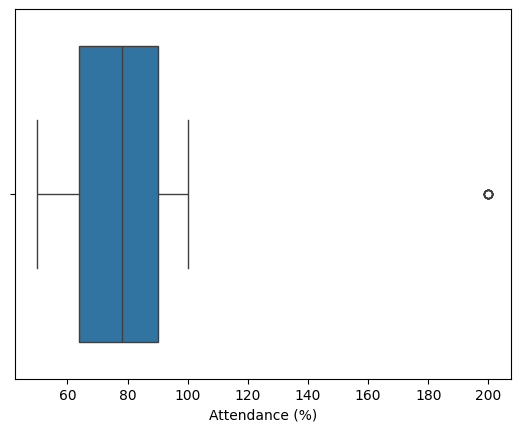

In [425]:
sns.boxplot(x=train_data['Attendance (%)'])
plt.show()

In [426]:
for index, row in train_data.iterrows():
  if "-" in str(row["Study Hours"]):
     print(row)

Gender                       Female
PreviousGrade                  70.0
ExtracurricularActivities       3.0
ParentalSupport                High
FinalGrade                     90.0
Study Hours                    -5.0
Attendance (%)                200.0
Online Classes Taken          False
Name: 148, dtype: object
Gender                        Male
PreviousGrade                 86.0
ExtracurricularActivities      NaN
ParentalSupport                Low
FinalGrade                    90.0
Study Hours                   -5.0
Attendance (%)               200.0
Online Classes Taken         False
Name: 125, dtype: object
Gender                         Male
PreviousGrade                  82.0
ExtracurricularActivities       1.0
ParentalSupport              Medium
FinalGrade                     85.0
Study Hours                    -5.0
Attendance (%)                200.0
Online Classes Taken           True
Name: 220, dtype: object
Gender                       Female
PreviousGrade                  77

In [427]:
most_frequent_extactivities = train_data['ExtracurricularActivities'].mode()[0]
train_data['ExtracurricularActivities'] = train_data['ExtracurricularActivities'].fillna(most_frequent_extactivities)
test_data['ExtracurricularActivities'] = test_data['ExtracurricularActivities'].fillna(most_frequent_extactivities)

In [428]:

most_frequent_classes = train_data['Online Classes Taken'].mode()[0]
train_data['Online Classes Taken'] = train_data['Online Classes Taken'].fillna(most_frequent_classes)
test_data['Online Classes Taken'] = test_data['Online Classes Taken'].fillna(most_frequent_classes)

/tmp/ipykernel_1173/478342433.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_data['Online Classes Taken'] = train_data['Online Classes Taken'].fillna(most_frequent_classes)
/tmp/ipykernel_1173/478342433.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_data['Online Classes Taken'] = test_data['Online Classes Taken'].fillna(most_frequent_classes)


In [429]:

most_frequent_support = train_data['ParentalSupport'].mode()[0]
train_data['ParentalSupport'] = train_data['ParentalSupport'].fillna(most_frequent_support)
test_data['ParentalSupport'] = test_data['ParentalSupport'].fillna(most_frequent_support)

In [430]:

most_frequent_gender = train_data['Gender'].mode()[0]
train_data['Gender'] = train_data['Gender'].fillna(most_frequent_gender)
test_data['Gender'] = test_data['Gender'].fillna(most_frequent_gender)

In [431]:
train_data['PreviousGrade'] = train_data['PreviousGrade'].fillna(train_data['PreviousGrade'].median())
test_data['PreviousGrade'] = test_data['PreviousGrade'].fillna(train_data['PreviousGrade'].median())

In [432]:
train_data['Study Hours'] = train_data['Study Hours'].fillna(train_data['Study Hours'].median())
test_data['Study Hours'] = test_data['Study Hours'].fillna(train_data['Study Hours'].median())

In [433]:
train_data['Attendance (%)'] = train_data['Attendance (%)'].fillna(train_data['Attendance (%)'].median())
test_data['Attendance (%)'] = test_data['Attendance (%)'].fillna(train_data['Attendance (%)'].median())

In [434]:
print(train_data.isnull().sum().sum(), test_data.isnull().sum().sum())   # يجب أن يكون 0 و 0
print(train_data[['Attendance (%)', 'Study Hours']].describe().loc[['min', 'max']])

0 11
     Attendance (%)  Study Hours
min            50.0         -5.0
max           200.0          5.0


In [435]:
# Fix the typo in test_data from cell E4YztnhfbBUh
test_data.drop('StudyHoursPerWeek', axis='columns', inplace=True, errors='ignore')

# Assert that the columns are now matching
assert list(train_data.columns) == list(test_data.columns)
print("true ", list(test_data.columns))

true  ['Gender', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']


In [436]:



for df in (train_data, test_data):
    df.loc[df['Attendance (%)'] > 100, 'Attendance (%)'] = np.nan
    df.loc[df['Study Hours'] < 0, 'Study Hours'] = np.nan


for c in ['Attendance (%)', 'Study Hours']:
    med = train_data[c].median()
    train_data[c] = train_data[c].fillna(med)
    test_data[c]  = test_data[c].fillna(med)


print(train_data[['Attendance (%)', 'Study Hours']].describe().loc[['min', 'max']])

     Attendance (%)  Study Hours
min            50.0          0.0
max           100.0          5.0


In [437]:
for d in (train_data, test_data):
    d['Online Classes Taken'] = d['Online Classes Taken'].map({True: 1, False: 0, 'True': 1, 'False': 0}).astype(int)
    d['ParentalSupport']      = d['ParentalSupport'].map({'Low': 0, 'Medium': 1, 'High': 2}).astype(int)
    d['Gender']               = d['Gender'].map({'Male': 0, 'Female': 1}).astype(int)

print(train_data.dtypes)

Gender                         int64
PreviousGrade                float64
ExtracurricularActivities    float64
ParentalSupport                int64
FinalGrade                   float64
Study Hours                  float64
Attendance (%)               float64
Online Classes Taken           int64
dtype: object


In [438]:
#define the columns
cols = ['PreviousGrade', 'ExtracurricularActivities',
        'Study Hours', 'Attendance (%)', 'ParentalSupport']

#call the sklearn library and import scaler
from sklearn.preprocessing import StandardScaler

#call the standard scaler
std_scaler = StandardScaler()

#fit the scaler on the training data only
std_scaler.fit(train_data[cols])

#transform the training and the test data
train_scaled = std_scaler.transform(train_data[cols])
test_scaled  = std_scaler.transform(test_data[cols])

#check the mean and the standard deviation
print(train_scaled.mean(axis=0).round(2))
print(train_scaled.std(axis=0).round(2))
print(test_scaled.mean(axis=0).round(2))

[ 0. -0. -0. -0.  0.]
[1. 1. 1. 1. 1.]
[-0.03  0.1  -0.05 -0.14  0.02]


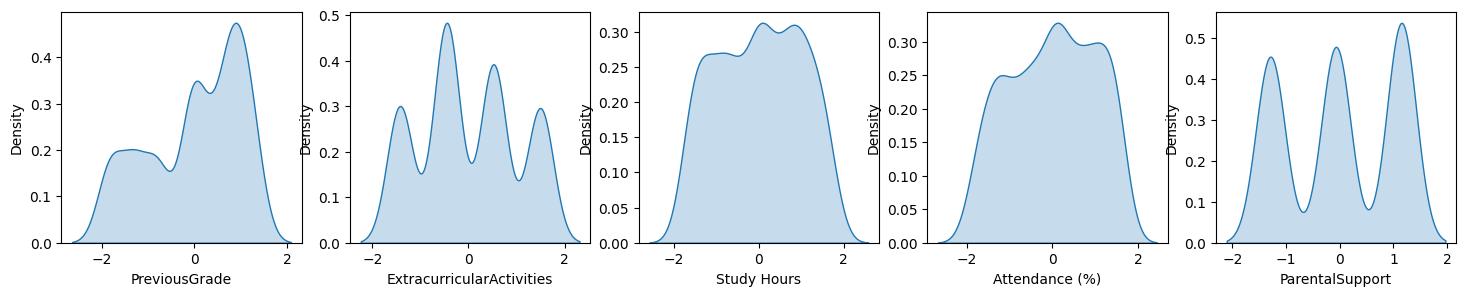

In [439]:
#plot the standardized values of every column
fig, axes = plt.subplots(1, 5, figsize=(18, 3))

for i, col in enumerate(cols):
    sns.kdeplot(train_scaled[:, i], fill=True, ax=axes[i])
    axes[i].set_xlabel(col)

plt.show()

In [440]:
#create a new column: 1 if the attendance is 75% or more, otherwise 0
train_data['HighAttendance'] = (train_data['Attendance (%)'] >= 75).astype(int)

#average final grade of each group
print(train_data.groupby('HighAttendance')['FinalGrade'].mean().round(2))

HighAttendance
0    79.74
1    80.22
Name: FinalGrade, dtype: float64


In [441]:
train_data = train_data.drop(columns=['HighAttendance'])

In [442]:
train_data.to_csv("train_clean.csv", index=False)
test_data.to_csv("test_clean.csv", index=False)

In [443]:
#Regression Model

In [444]:
#MODEL LINEAR REGRESSION

In [445]:
target = "FinalGrade"

X_train = train_data.drop(columns=target)
y_train = train_data[target]
X_test  = test_data.drop(columns=target)
y_test  = test_data[target]

print(X_train.shape, X_test.shape)
print(list(X_train.columns))

(676, 7) (284, 7)
['Gender', 'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport', 'Study Hours', 'Attendance (%)', 'Online Classes Taken']


In [446]:
X = X_train.copy()
y = y_train.copy()

In [447]:
X

,Gender,PreviousGrade,ExtracurricularActivities,ParentalSupport,Study Hours,Attendance (%),Online Classes Taken
541,0,60.0,1.0,2,2.8,92.0,1
440,0,70.0,0.0,2,0.5,80.0,1
482,1,60.0,0.0,2,0.4,90.0,1
422,0,77.0,1.0,1,3.4,65.0,1
778,0,90.0,1.0,0,0.6,84.0,1
...,...,...,...,...,...,...,...
106,0,82.0,1.0,1,3.4,60.0,1
270,1,85.0,2.0,0,2.6,90.0,0
860,1,78.0,1.0,0,2.6,76.0,0
435,1,77.0,1.0,1,3.0,91.0,0


In [448]:
X["intercept"] =1

In [449]:
X=X[["intercept","Gender","PreviousGrade","ExtracurricularActivities","ParentalSupport","Study Hours","Attendance (%)","Online Classes Taken"]]

In [450]:
X_T=X.T

In [451]:
B= np.linalg.inv(X_T @ X) @ X_T @ y

In [452]:
B

,0
0,77.687513
1,0.887344
2,-0.005448
3,-0.238666
4,-0.653725
5,0.273731
6,0.031706
7,0.585782


In [453]:
B.index = X.columns

In [454]:
B

,0
intercept,77.687513
Gender,0.887344
PreviousGrade,-0.005448
ExtracurricularActivities,-0.238666
ParentalSupport,-0.653725
Study Hours,0.273731
Attendance (%),0.031706
Online Classes Taken,0.585782


In [455]:
predictions = X @ B

In [456]:
SSR = ((y - predictions) ** 2).sum()

In [457]:
SST=((y - y.mean()) ** 2).sum()

In [458]:
SSR

np.float64(58937.33116791935)

In [459]:
SST

np.float64(59598.880177514795)

In [460]:
R2= 1- (SSR/SST)

In [461]:
R2

np.float64(0.011100024155236254)

In [462]:
MAE = np.abs(y - predictions).mean()

In [463]:
MAE

np.float64(7.933447119896962)

In [464]:
RMSE = np.sqrt(((y - predictions) ** 2).mean())

In [465]:
base = np.full(len(y), y_train.mean())
print(np.abs(y - base).mean(), np.sqrt(((y - base) ** 2).mean()))

7.9488156927278455 9.389569954541843


In [466]:
#from sklearn.linear_model import LinearRegression
#lr= LinearRegression()
#lr.fit(X_train,y_train)
#LinearRegression()
#lr.coef_
#lr.intercept_

In [ ]:
#2 MODAL RANDOM FORSET REGRESSION

In [468]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

predictions_rf = rf.predict(X_test)

In [469]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

r2_rf = r2_score(y_test, predictions_rf)

mae_rf = mean_absolute_error(y_test, predictions_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, predictions_rf)
)

print("R2:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

R2: -0.058243109377427604
MAE: 8.529859154929577
RMSE: 9.999563652451872


In [472]:
print(train_data.describe().T)

                           count       mean        std   min   25%   50%  \
Gender                     676.0   0.439349   0.496675   0.0   0.0   0.0   
PreviousGrade              676.0  77.707101   9.731659  60.0  70.0  78.0   
ExtracurricularActivities  676.0   1.464497   1.030029   0.0   1.0   1.0   
ParentalSupport            676.0   1.056213   0.819994   0.0   0.0   1.0   
FinalGrade                 676.0  80.013314   9.396523  62.0  72.0  80.0   
Study Hours                676.0   2.498817   1.420432   0.0   1.3   2.5   
Attendance (%)             676.0  76.674556  14.447166  50.0  65.0  78.0   
Online Classes Taken       676.0   0.485207   0.500151   0.0   0.0   0.0   

                            75%    max  
Gender                      1.0    1.0  
PreviousGrade              86.0   90.0  
ExtracurricularActivities   2.0    3.0  
ParentalSupport             2.0    2.0  
FinalGrade                 88.0   92.0  
Study Hours                 3.7    5.0  
Attendance (%)             8

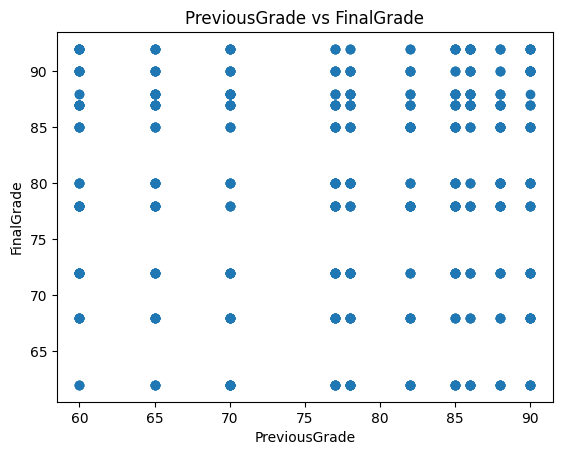

In [473]:
import matplotlib.pyplot as plt

plt.scatter(
    train_data['PreviousGrade'],
    train_data['FinalGrade']
)

plt.xlabel('PreviousGrade')
plt.ylabel('FinalGrade')
plt.title('PreviousGrade vs FinalGrade')

plt.show()

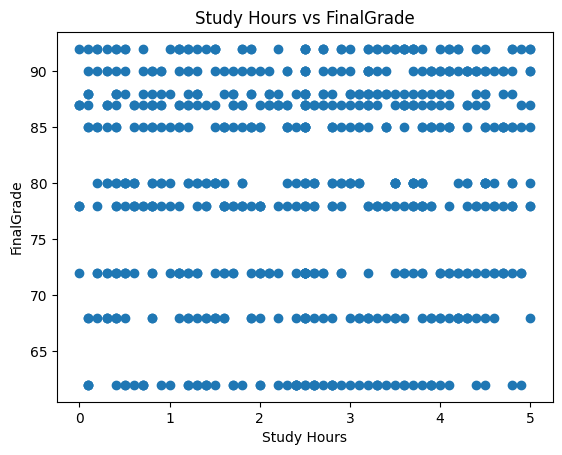

In [474]:
plt.scatter(
    train_data['Study Hours'],
    train_data['FinalGrade']
)

plt.xlabel('Study Hours')
plt.ylabel('FinalGrade')
plt.title('Study Hours vs FinalGrade')

plt.show()

In [475]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

print("Baseline R2:",
      r2_score(y_test, baseline_predictions))

print("Baseline MAE:",
      mean_absolute_error(y_test, baseline_predictions))

Baseline R2: -3.451686409272625e-05
Baseline MAE: 8.324318693224436


In [479]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Linear Regression
lr_train_pred = lr.predict(X_train)
lr_test_pred = lr.predict(X_test)

print("Linear Regression")
print("Train R2:", r2_score(y_train, lr_train_pred))
print("Test R2:", r2_score(y_test, lr_test_pred))

# Random Forest
rf_train_pred = rf.predict(X_train)
rf_test_pred = rf.predict(X_test)

print("\nRandom Forest")
print("Train R2:", r2_score(y_train, rf_train_pred))
print("Test R2:", r2_score(y_test, rf_test_pred))

Linear Regression
Train R2: 0.011100024155236143
Test R2: -0.002729200062538295

Random Forest
Train R2: 0.8458639361572136
Test R2: -0.058243109377427604


In [ ]:
#MODEL3 RIDGE REGRESSION

In [480]:
X1=X_train.copy()
y1=y_train.copy()

In [482]:
X1_mean = X1.mean()
X1_std = X1.std()

X1 = (X1 - X1_mean) / X1_std

In [483]:
X1.describe()

,Gender,PreviousGrade,ExtracurricularActivities,ParentalSupport,Study Hours,Attendance (%),Online Classes Taken
count,6.760000e+02,6.760000e+02,6.760000e+02,6.760000e+02,6.760000e+02,6.760000e+02,6.760000e+02
mean,-9.722663e-17,5.544546e-16,-1.051099e-16,-2.956215e-18,-2.364972e-17,-2.660594e-17,-1.103654e-16
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-8.845801e-01,-1.819536e+00,-1.421802e+00,-1.288073e+00,-1.759194e+00,-1.846352e+00,-9.701208e-01
25%,-8.845801e-01,-7.919616e-01,-4.509553e-01,-1.288073e+00,-8.439800e-01,-8.080863e-01,-9.701208e-01
50%,-8.845801e-01,3.009758e-02,-4.509553e-01,-6.855292e-02,8.331491e-04,9.174421e-02,-9.701208e-01
75%,1.128808e+00,8.521568e-01,5.198911e-01,1.150967e+00,8.456463e-01,8.531392e-01,1.029275e+00
max,1.128808e+00,1.263186e+00,1.490737e+00,1.150967e+00,1.760861e+00,1.614534e+00,1.029275e+00


In [484]:
X1["intercept"] = 1

In [485]:
X1=X1[["intercept","Gender","PreviousGrade","ExtracurricularActivities","ParentalSupport","Study Hours","Attendance (%)","Online Classes Taken"]]

In [486]:
X1.T

,541,440,482,422,778,949,334,576,934,567,...,466,121,20,700,71,106,270,860,435,102
intercept,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Gender,-0.884580,-0.884580,1.128808,-0.884580,-0.884580,-0.884580,1.128808,1.128808,1.128808,1.128808,...,-0.884580,1.128808,-0.884580,1.128808,1.128808,-0.884580,1.128808,1.128808,1.128808,-0.884580
PreviousGrade,-1.819536,-0.791962,-1.819536,-0.072660,1.263186,-0.791962,1.263186,0.852157,-1.305749,1.263186,...,-0.791962,0.030098,-0.072660,0.749399,-0.072660,0.441127,0.749399,0.030098,-0.072660,-1.819536
ExtracurricularActivities,-0.450955,-1.421802,-1.421802,-0.450955,-0.450955,-0.450955,1.490737,-0.450955,-0.450955,0.519891,...,-1.421802,-1.421802,0.519891,1.490737,0.519891,-0.450955,0.519891,-0.450955,-0.450955,-0.450955
ParentalSupport,1.150967,1.150967,1.150967,-0.068553,-1.288073,-1.288073,-1.288073,1.150967,1.150967,1.150967,...,-0.068553,1.150967,1.150967,-1.288073,-0.068553,-0.068553,-1.288073,-1.288073,-0.068553,-1.288073
Study Hours,0.212036,-1.407189,-1.477590,0.634443,-1.336788,-0.351172,-0.491975,0.634443,-1.336788,0.212036,...,-1.266387,0.986449,-1.195986,1.549657,0.493641,0.634443,0.071234,0.071234,0.352839,1.338454
Attendance (%),1.060792,0.230180,0.922357,-0.808086,0.507051,-0.669651,1.614534,-0.461998,-0.323562,-1.500264,...,1.406881,-0.808086,-1.154175,0.437833,0.160962,-1.154175,0.922357,-0.046691,0.991575,-1.707917
Online Classes Taken,1.029275,1.029275,1.029275,1.029275,1.029275,1.029275,1.029275,-0.970121,1.029275,-0.970121,...,1.029275,-0.970121,-0.970121,-0.970121,1.029275,1.029275,-0.970121,-0.970121,-0.970121,1.029275


In [491]:
alpha =1000
I = np.identity(X1.shape[1])
I[0][0]=0

In [492]:
penatly = alpha * I

In [494]:
B1= np.linalg.inv(X1.T @ X1 + penatly) @ X1.T @ y1

In [495]:
B1

,0
0,80.013314
1,0.439308
2,-0.052834
3,-0.245056
4,-0.534394
5,0.387770
6,0.456645
7,0.292259


In [496]:
B1.index = ["intercept","Gender","PreviousGrade","ExtracurricularActivities","ParentalSupport","Study Hours","Attendance (%)","Online Classes Taken"]

In [497]:
B1

,0
intercept,80.013314
Gender,0.439308
PreviousGrade,-0.052834
ExtracurricularActivities,-0.245056
ParentalSupport,-0.534394
Study Hours,0.387770
Attendance (%),0.456645
Online Classes Taken,0.292259


In [501]:
test_X1 = (X_test - X1_mean) / X1_std
test_X1["intercept"] = 1
test_X1=test_X1[["intercept","Gender","PreviousGrade","ExtracurricularActivities","ParentalSupport","Study Hours","Attendance (%)","Online Classes Taken"]]

In [502]:
test_X1

,intercept,Gender,PreviousGrade,ExtracurricularActivities,ParentalSupport,Study Hours,Attendance (%),Online Classes Taken
521,1,1.128808,0.030098,-1.421802,-1.288073,-1.618392,-1.154175,1.029275
737,1,1.128808,-1.819536,-0.450955,1.150967,1.338454,-0.531215,-0.970121
740,1,1.128808,0.852157,-0.450955,-1.288073,1.056850,-1.500264,1.029275
660,1,-0.884580,-1.305749,-0.450955,1.150967,-0.773579,-0.046691,-0.970121
411,1,1.128808,-1.819536,0.519891,-1.288073,-1.688793,0.437833,-0.970121
...,...,...,...,...,...,...,...,...
468,1,1.128808,0.030098,-1.421802,1.150967,-1.547991,-0.738869,-0.970121
935,1,-0.884580,0.852157,-0.450955,-0.068553,-0.773579,0.299397,1.029275
428,1,-0.884580,-1.305749,-0.450955,-1.288073,-1.407189,-0.254344,1.029275
7,1,1.128808,-0.072660,-0.450955,-0.068553,-1.055183,-0.461998,1.029275


In [503]:
prodictions1= test_X1 @ B1

In [504]:
prodictions1

,0
521,80.690581
737,80.093688
740,81.288575
660,78.584318
411,80.427821
...,...
468,79.019777
935,79.864394
428,80.131551
7,80.340869


In [506]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1000)
ridge.fit(X_train, y_train)

Ridge(alpha=2)

In [507]:
ridge.coef_

array([ 0.87663378, -0.00541597, -0.23803087, -0.6505974 ,  0.27345477,
        0.03170389,  0.57911126])

In [508]:
ridge.intercept_

np.float64(77.6896054005212)

In [509]:
sklearn_predictions = ridge.predict(X_test)

In [510]:
prodictions1 - sklearn_predictions

,0
521,0.010752
737,0.000863
740,0.009496
660,-0.006356
411,0.003833
...,...
468,0.002685
935,-0.000773
428,0.001791
7,0.008449


In [514]:
from sklearn.metrics import  mean_absolute_error
error = []
alphas =[10**i for i in range(-2,4)]
for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    sklearn_predictions = ridge.predict(X_test)
    error.append(mean_absolute_error(y_test, sklearn_predictions))

In [515]:
error

[8.384106203425098,
 8.38409371614038,
 8.383969271511193,
 8.38276593438307,
 8.374488721437418,
 8.355520023962587]

In [516]:
alphas

[0.01, 0.1, 1, 10, 100, 1000]

In [522]:
SSR = ((y_test - prodictions1) ** 2).sum()
SST = ((y_test - y_test.mean()) ** 2).sum()
R2 = 1 - (SSR / SST)
MAE = np.abs(y_test - prodictions1).mean()
RMSE = np.sqrt(((y_test - prodictions1) ** 2).mean())

print("R2:", R2)
print("MAE:", MAE)
print("RMSE:", RMSE)

R2: -0.002693976390347741
MAE: nan
RMSE: nan
